# Statistical and Correlation Analysis of Startup Funding

## 1. Introduction

Statistical analysis helps us understand the characteristics, distribution and relationships within the startup funding dataset.

In this notebook, we will perform statistical analysis and correlation analysis to identify meaningful patterns and relationships among the available variables.

### Objectives

- Calculate statistical measures such as mean, median, standard deviation and quartiles.
- Understand the distribution of startup funding amounts.
- Identify relationships between numerical variables.
- Visualize correlations using a correlation matrix and heatmap.
- Interpret the results to support further feature engineering and modeling.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Loading the Cleaned Dataset

The cleaned dataset generated during the data preprocessing stage is loaded for statistical and correlation analysis. This avoids repeating the data cleaning operations.

In [2]:
file_path = "../data/processed/startup_funding_cleaned.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (3044, 21)


,Sr No,Date dd/mm/yyyy,Startup Name,Industry Vertical,SubVertical,City Location,Investors Name,InvestmentnType,Amount in USD,Remarks,...,Date_Cleaned,Amount_Approximate,Amount_Cleaned,City_Cleaned,Industry_Cleaned,SubVertical_Cleaned,Investment_Type_Cleaned,Investors_Cleaned,Remarks_Cleaned,Is_Outlier
0,1,09/01/2020,BYJU’S,E-Tech,E-learning,Bengaluru,Tiger Global Management,Private Equity Round,"20,00,00,000",NaN,...,2020-01-09,False,200000000.0,Bengaluru,E-Tech,E-Learning,Private Equity,Tiger Global Management,NaN,True
1,2,13/01/2020,Shuttl,Transportation,App based shuttle service,Gurgaon,Susquehanna Growth Equity,Series C,"80,48,394",NaN,...,2020-01-13,False,8048394.0,Gurugram,Transportation,App Based Shuttle Service,Series C,Susquehanna Growth Equity,NaN,False
2,3,09/01/2020,Mamaearth,E-commerce,Retailer of baby and toddler products,Bengaluru,Sequoia Capital India,Series B,"1,83,58,860",NaN,...,2020-01-09,False,18358860.0,Bengaluru,Ecommerce,Retailer Of Baby And Toddler Products,Series B,Sequoia Capital India,NaN,False
3,4,02/01/2020,https://www.wealthbucket.in/,FinTech,Online Investment,New Delhi,Vinod Khatumal,Pre-series A,"30,00,000",NaN,...,2020-01-02,False,3000000.0,New Delhi,Fintech,Online Investment,Pre-Series A,Vinod Khatumal,NaN,False
4,5,02/01/2020,Fashor,Fashion and Apparel,Embroiled Clothes For Women,Mumbai,Sprout Venture Partners,Seed Round,"18,00,000",NaN,...,2020-01-02,False,1800000.0,Mumbai,Fashion And Apparel,Embroiled Clothes For Women,Seed Round,Sprout Venture Partners,NaN,False


In [3]:
print("Column Data Types:")
print(df.dtypes)

Column Data Types:
Sr No                        int64
Date dd/mm/yyyy             object
Startup Name                object
Industry Vertical           object
SubVertical                 object
City  Location              object
Investors Name              object
InvestmentnType             object
Amount in USD               object
Remarks                     object
Date_Converted              object
Date_Cleaned                object
Amount_Approximate            bool
Amount_Cleaned             float64
City_Cleaned                object
Industry_Cleaned            object
SubVertical_Cleaned         object
Investment_Type_Cleaned     object
Investors_Cleaned           object
Remarks_Cleaned             object
Is_Outlier                  object
dtype: object


In [4]:
df["Year"] = pd.to_datetime(
    df["Date_Cleaned"], errors="coerce"
).dt.year

print("Year column created successfully!")
display(df[["Date_Cleaned", "Year"]].head())

Year column created successfully!


,Date_Cleaned,Year
0,2020-01-09,2020
1,2020-01-13,2020
2,2020-01-09,2020
3,2020-01-02,2020
4,2020-01-02,2020


## 4. Statistical Analysis of Startup Funding Amounts

Statistical analysis helps us understand the distribution and characteristics of startup funding amounts.

We calculate important statistical measures such as count, mean, standard deviation, minimum, maximum, median and quartiles.

In [5]:
print("Statistical Summary of Funding Amounts:")

display(df["Amount_Cleaned"].describe())

print("Median Funding Amount:")
print(df["Amount_Cleaned"].median())

print("Skewness of Funding Amounts:")
print(df["Amount_Cleaned"].skew())

Statistical Summary of Funding Amounts:


count    2.066000e+03
mean     1.842792e+07
std      1.213441e+08
min      1.600000e+04
25%      4.712500e+05
50%      1.725000e+06
75%      8.000000e+06
max      3.900000e+09
Name: Amount_Cleaned, dtype: float64

Median Funding Amount:
1725000.0
Skewness of Funding Amounts:
22.14114794409037


## 5. Distribution of Funding Amounts

A histogram is used to visualize the distribution of startup funding amounts and understand how frequently different funding ranges occur.

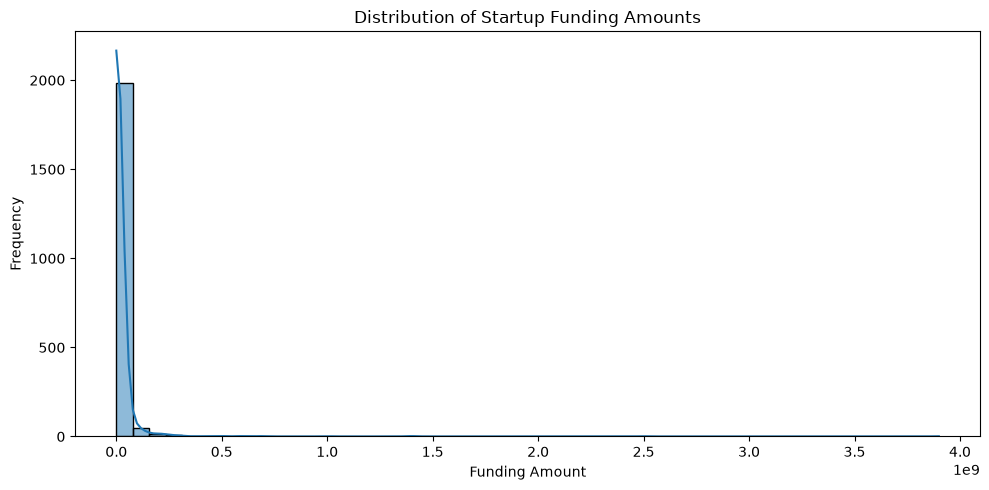

In [6]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["Amount_Cleaned"].dropna(),
    bins=50,
    kde=True
)

plt.title("Distribution of Startup Funding Amounts")
plt.xlabel("Funding Amount")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

## 5. Correlation Analysis

Correlation analysis helps us understand the relationship between numerical variables.

In this project, we examine the relationship between the year of funding and the funding amount to identify whether funding amounts show a linear relationship with time.

In [7]:
correlation_data = df[
    ["Year", "Amount_Cleaned"]
].dropna()

print("Selected numerical features:")
display(correlation_data.head())

print("\nShape of correlation dataset:")
print(correlation_data.shape)

Selected numerical features:


,Year,Amount_Cleaned
0,2020,200000000.0
1,2020,8048394.0
2,2020,18358860.0
3,2020,3000000.0
4,2020,1800000.0



Shape of correlation dataset:
(2066, 2)


## 6. Pearson Correlation Coefficient

Pearson correlation measures the strength and direction of a linear relationship between two numerical variables.

The correlation coefficient ranges from -1 to +1.

- +1 indicates a perfect positive correlation.
- -1 indicates a perfect negative correlation.
- 0 indicates no linear correlation.

In [8]:
correlation_value = correlation_data[
    "Year"
].corr(correlation_data["Amount_Cleaned"])

print("Correlation between Year and Funding Amount:")
print(correlation_value)

Correlation between Year and Funding Amount:
0.09997416008762829


### Observation

The Pearson correlation coefficient between Year and Amount_Cleaned is approximately 0.10.

This indicates a very weak positive linear relationship between the year and startup funding amount. Therefore, the year alone does not show a strong linear relationship with individual funding amounts in this dataset.

## 7. Visualization of Correlation

A scatter plot is used to visualize the relationship between the year of funding and the funding amount.

A regression line is added to identify the overall linear trend in the data.

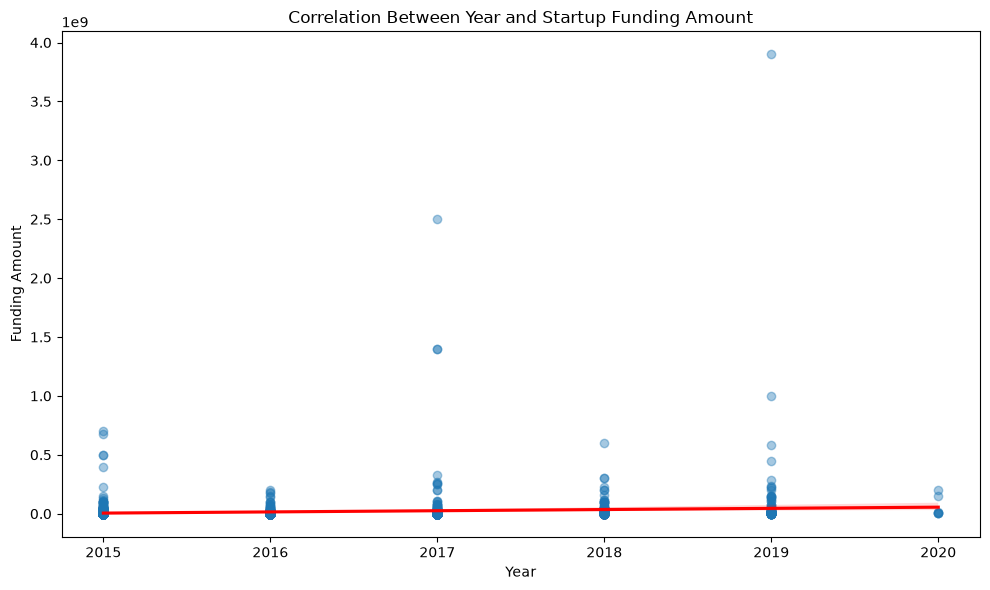

In [9]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=correlation_data,
    x="Year",
    y="Amount_Cleaned",
    scatter_kws={"alpha": 0.4},
    line_kws={"color": "red"}
)

plt.title("Correlation Between Year and Startup Funding Amount")
plt.xlabel("Year")
plt.ylabel("Funding Amount")
plt.tight_layout()
plt.show()

## 8. Spearman Rank Correlation

Spearman correlation measures the strength and direction of a relationship between two variables using their ranks instead of their original values.

It is useful when data contains extreme values or does not follow a normal distribution.

In [10]:
spearman_value = correlation_data[
    "Year"
].corr(
    correlation_data["Amount_Cleaned"],
    method="spearman"
)

print("Spearman Correlation between Year and Funding Amount:")
print(spearman_value)

Spearman Correlation between Year and Funding Amount:
0.18095283305064258


### Observation

The Spearman correlation coefficient between Year and Amount_Cleaned is approximately 0.18.

This indicates a weak positive relationship between the two variables based on their ranks. The result is slightly higher than the Pearson correlation coefficient, suggesting that the relationship may be somewhat clearer when ranks are considered instead of raw funding amounts.

## 9. Comparison of Pearson and Spearman Correlation

Pearson and Spearman correlation methods are compared to understand the relationship between funding year and funding amount using two different approaches.

In [11]:
correlation_comparison = pd.DataFrame({
    "Correlation Method": ["Pearson", "Spearman"],
    "Correlation Value": [
        correlation_value,
        spearman_value
    ]
})

display(correlation_comparison)

,Correlation Method,Correlation Value
0,Pearson,0.099974
1,Spearman,0.180953


### Observation

Pearson correlation (0.099974) and Spearman correlation (0.180953) both indicate a weak positive relationship between funding year and funding amount.

Spearman correlation is slightly higher than Pearson correlation, suggesting a somewhat stronger positive association when ranked values are considered.

## 10. Correlation Heatmap

A correlation heatmap is a graphical representation of correlation values between numerical variables.

Different colors represent the strength and direction of relationships between variables.

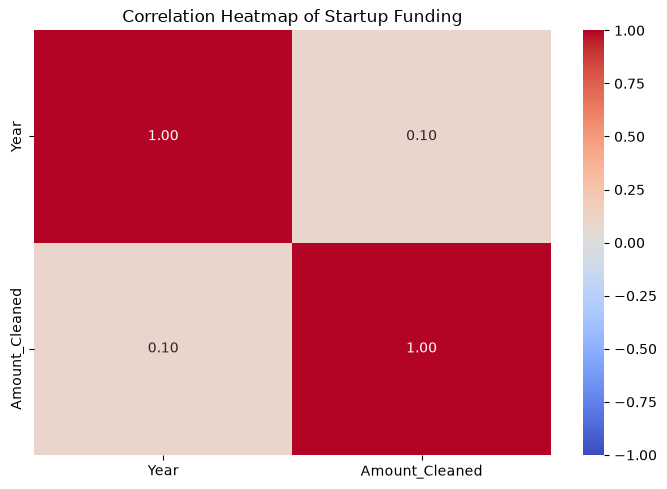

In [12]:
correlation_matrix = correlation_data.corr(
    method="pearson"
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Startup Funding")
plt.tight_layout()
plt.show()

## 11. Key Findings

The following observations were identified through statistical and correlation analysis:

1. The average startup funding amount is higher than the median, indicating the influence of large funding records.
2. The funding amount distribution is highly right-skewed.
3. The Pearson correlation coefficient between Year and Amount_Cleaned is approximately 0.10, indicating a very weak positive linear relationship.
4. The Spearman correlation coefficient is approximately 0.18, indicating a weak positive relationship based on ranks.
5. Both correlation methods show that the year alone has a weak relationship with individual funding amounts.

## 12. Conclusion

Statistical and correlation analysis helped us understand the distribution of startup funding amounts and the relationship between funding year and funding amount.

The analysis revealed that funding amounts vary considerably, with a small number of very large investments influencing the overall distribution.

The correlation results indicate a weak positive relationship between funding year and funding amount.

These findings provide a foundation for further feature engineering and machine learning analysis.